**Autor:** Andrés Alejandro Rodríguez Lozano · @Andalejo1109

# Capítulo 10 — Ahorrar US$1.000/mes al 4% vs invertir US$10.000 una vez (40 años)

Replicamos y ampliamos la "carrera" de *race_charts*: **ahorrar US$1.000 al mes vs invertir US$10.000 una sola vez en el S&P 500**, de sep‑1986 a sep‑2026. En el video el inversor termina con ~US$621K y el ahorrador (0%, "bajo el colchón") con US$490K.

Aquí añadimos:
1. **Ahorrador al 4% anual** (capitalización mensual) y el ahorrador al 0% como referencia.
2. **Inversor A**: US$10.000 una vez en mi portafolio actual (eToro, 5‑oct‑2026): SPYG 30,51%, SMH 21,76%, BRK.B 20,40%, IEMG 20,15%, VTI 7,18%, rebalanceo anual.
3. **Inversor B**: US$10.000 una vez en el S&P 500 (retorno total).

> ⚠️ Contenido educativo, no es asesoría de inversión. Rentabilidades pasadas no garantizan resultados futuros.

## Paso 1 — Librerías y parámetros

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%config InlineBackend.figure_formats = ['svg']
plt.rcParams['text.parse_math'] = False   # para que el símbolo $ no active fórmulas
# Pesos actuales del portafolio (eToro, 5-oct-2026)
PESOS = {'SPYG':.3051,'SMH':.2176,'BRK':.2040,'IEMG':.2015,'VTI':.0718}
INICIO, FIN = '1986-09', '2026-09'   # 480 meses
CAPITAL, APORTE = 10_000, 1_000
r_ahorro = 1.04**(1/12) - 1          # 4% anual -> tasa mensual equivalente
print(f'Tasa mensual del ahorrador: {r_ahorro:.5%}')

Tasa mensual del ahorrador: 0.32737%


## Paso 2 — Datos
Precios mensuales ajustados (dividendos incluidos) de Yahoo Finance, guardados en `data40/mensual_raw.csv` (los descarga `yfinance`).
- **BRK.B** se lanzó en 1996; usamos **BRK‑A** (la misma empresa, misma economía) como historia real desde 1985.
- **S&P 500**: `^SP500TR` (retorno total) desde ene‑1988; antes, `^GSPC` (solo precio, sin dividendos ⇒ ligeramente conservador para 1986‑87).

In [2]:
raw = pd.read_csv('../data40/mensual_raw.csv', index_col=0, parse_dates=True)
raw.index = raw.index.to_period('M')      # cada barra = cierre de fin de mes
raw = raw.loc[:FIN]                       # quitamos el mes en curso (incompleto)
ret = raw.pct_change()
# S&P 500: retorno total cuando existe, precio antes
sp = ret['^SP500TR'].combine_first(ret['^GSPC'])
activos = pd.DataFrame({'SPYG':ret['SPYG'],'SMH':ret['SMH'],'BRK':ret['BRK-A'],
                        'IEMG':ret['IEMG'],'VTI':ret['VTI']})
meses = pd.period_range(INICIO, FIN, freq='M')[1:]   # 480 retornos: oct-86 ... sep-26
activos, sp = activos.reindex(meses), sp.reindex(meses)
print(len(meses), 'meses')

480 meses


## Paso 3 — Regla de relleno (backfill)
Para los meses antes de que un activo existiera usamos **su propio retorno mensual promedio geométrico** (constante). Desde su lanzamiento usamos sus **retornos reales** (con caídas).

Variante de **sensibilidad**: antes del lanzamiento usamos el **retorno real del S&P 500** de ese mes.

> ⚠️ La parte rellenada con el promedio **no tiene caídas** (1987, 2000‑02 para ETFs posteriores…), y un promedio constante no refleja lo que realmente pasó. Ojo: en esta muestra los promedios de SPYG, SMH y VTI se miden desde 2000‑2001 (arrancan con la burbuja punto com) y el de IEMG desde 2012, así que resultan **más bajos** que el mercado alcista 1986‑2000; por eso la variante con el S&P real termina **más alta**. Ninguna de las dos es historia real: tómalo como ilustración.

In [3]:
def geo_mean(r):
    r = r.dropna(); return (1+r).prod()**(1/len(r)) - 1
fill_prom, fill_sp, tabla = activos.copy(), activos.copy(), []
for a in activos:
    real = ret[{'BRK':'BRK-A'}.get(a,a)].dropna()
    g = geo_mean(real.loc['1986-10':])
    falt = activos[a].isna()
    fill_prom.loc[falt, a] = g            # promedio constante
    fill_sp.loc[falt, a] = sp[falt]       # S&P 500 real del mes
    tabla.append({'Activo':a if a!='BRK' else 'BRK.B (vía BRK-A)',
                  'Primer retorno real':str(activos[a].first_valid_index()),
                  'Meses rellenados':int(falt.sum()),
                  'Prom. mensual geo':f'{g:.2%}', 'Equiv. anual':f'{(1+g)**12-1:.1%}'})
tabla_backfill = pd.DataFrame(tabla); tabla_backfill

,Activo,Primer retorno real,Meses rellenados,Prom. mensual geo,Equiv. anual
0,SPYG,2000-11,169,0.65%,8.1%
1,SMH,2000-07,165,0.87%,10.9%
2,BRK.B (vía BRK-A),1986-10,0,1.18%,15.2%
3,IEMG,2012-11,313,0.52%,6.4%
4,VTI,2001-07,177,0.77%,9.7%


## Paso 4 — Simulación de los cuatro participantes
Rebalanceo anual: cada enero los pesos vuelven a su objetivo; entre rebalanceos cada posición deriva con su retorno.

In [4]:
def portafolio(R):
    w = np.array(list(PESOS.values())); pos = CAPITAL*w; vals=[CAPITAL]
    for p, fila in R.iterrows():
        if p.month == 1: pos = pos.sum()*w          # rebalanceo anual
        pos = pos*(1+fila.values); vals.append(pos.sum())
    return np.array(vals)
idx = pd.period_range(INICIO, FIN, freq='M')
res = pd.DataFrame(index=idx)
res['Ahorrador 0%'] = CAPITAL + APORTE*np.arange(481)
a=[CAPITAL]
for _ in range(480): a.append(a[-1]*(1+r_ahorro)+APORTE)
res['Ahorrador 4%'] = a
res['Mi portafolio'] = portafolio(fill_prom)
res['Mi portafolio (sens. S&P)'] = portafolio(fill_sp)
res['S&P 500'] = CAPITAL*np.r_[1,(1+sp).cumprod().values]
res.iloc[-1].map('US$ {:,.0f}'.format)

Ahorrador 0%                   US$ 490,000
Ahorrador 4%                 US$ 1,209,074
Mi portafolio                  US$ 632,041
Mi portafolio (sens. S&P)    US$ 1,131,579
S&P 500                        US$ 740,695
Name: 2026-09, dtype: str

## Paso 5 — Cortes en el tiempo y cruce
¿Cuánto tenía cada uno a los 5, 10, 20, 30 y 40 años? ¿En qué mes cada inversor supera al ahorrador del 4% (y se mantiene arriba)?

In [5]:
cortes = res.iloc[[60,120,240,360,480]].copy(); cortes.index=[f'{y} años ({p})' for y,p in zip([5,10,20,30,40],cortes.index)]
display(cortes.round(0).astype(int).map('{:,}'.format))
for ahorr in ['Ahorrador 4%','Ahorrador 0%']:
    for c in ['Mi portafolio','Mi portafolio (sens. S&P)','S&P 500']:
        arriba = res[c] > res[ahorr]
        primero = arriba.idxmax() if arriba.any() else 'nunca'
        definitivo = (arriba[::-1].idxmin() + 1) if arriba.iloc[-1] else 'nunca'
        print(f'{c} vs {ahorr}: primer cruce {primero}, arriba definitivamente desde {definitivo}')

,Ahorrador 0%,Ahorrador 4%,Mi portafolio,Mi portafolio (sens. S&P),S&P 500
5 años (1991-09),"70,000","78,346","18,750","21,969","19,101"
10 años (1996-09),"130,000","161,498","34,608","50,891","38,802"
20 años (2006-09),"250,000","385,753","48,818","93,675","88,436"
30 años (2016-09),"370,000","717,705","109,251","195,599","177,877"
40 años (2026-09),"490,000","1,209,074","632,041","1,131,579","740,695"


Mi portafolio vs Ahorrador 4%: primer cruce nunca, arriba definitivamente desde nunca
Mi portafolio (sens. S&P) vs Ahorrador 4%: primer cruce nunca, arriba definitivamente desde nunca
S&P 500 vs Ahorrador 4%: primer cruce nunca, arriba definitivamente desde nunca
Mi portafolio vs Ahorrador 0%: primer cruce 2025-09, arriba definitivamente desde 2025-09
Mi portafolio (sens. S&P) vs Ahorrador 0%: primer cruce 2021-01, arriba definitivamente desde 2023-03
S&P 500 vs Ahorrador 0%: primer cruce 2024-02, arriba definitivamente desde 2024-02


## Paso 6 — Gráfico tipo carrera (tema oscuro)

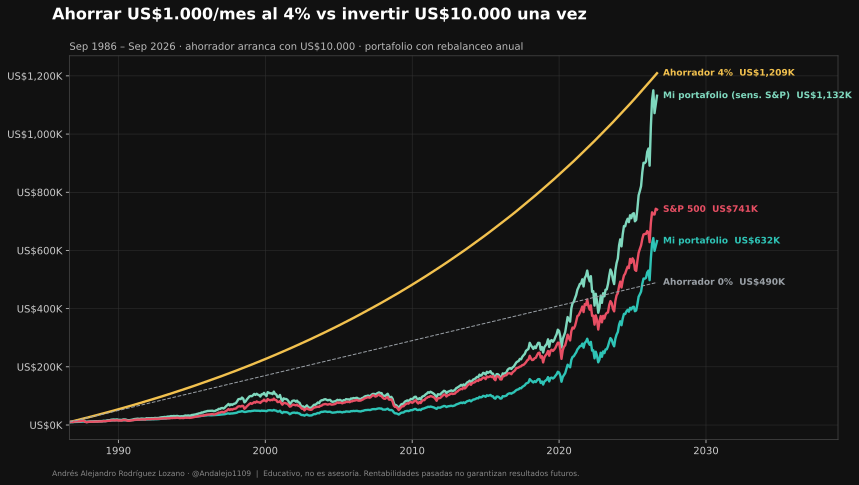

In [6]:
COL = {'Ahorrador 4%':'#f2c14e','Mi portafolio':'#2ec4b6','Mi portafolio (sens. S&P)':'#7fd8be','S&P 500':'#e94f64','Ahorrador 0%':'#9aa0a6'}
FIRMA = 'Andrés Alejandro Rodríguez Lozano · @Andalejo1109  |  Educativo, no es asesoría. Rentabilidades pasadas no garantizan resultados futuros.'
def grafico(n=480, ax=None):
    x = res.index[:n+1].to_timestamp()
    for c,col in COL.items():
        y = res[c].iloc[:n+1]
        ax.plot(x, y, color=col, lw=1 if '0%' in c else 2.4, ls='--' if '0%' in c else '-')
        ax.annotate(f'{c}  US${y.iloc[-1]/1e3:,.0f}K', (x[-1], y.iloc[-1]), xytext=(6,0), textcoords='offset points', color=col, fontsize=9, va='center', weight='bold')
    ax.set_facecolor('#111'); ax.tick_params(colors='#ccc'); ax.grid(color='#333', lw=.5)
    for s in ax.spines.values(): s.set_color('#444')
    ax.yaxis.set_major_formatter(lambda v,_: f'US${v/1e3:,.0f}K')
    ax.set_xlim(res.index[0].to_timestamp(), res.index[-1].to_timestamp()+pd.Timedelta(days=4500))
def figura(n=480):
    fig, ax = plt.subplots(figsize=(12,6.75), facecolor='#111'); grafico(n, ax)
    fig.suptitle('Ahorrar US$1.000/mes al 4% vs invertir US$10.000 una vez', color='w', fontsize=16, weight='bold', x=.06, ha='left')
    ax.set_title(f'Sep 1986 – {res.index[n].strftime("%b %Y")} · ahorrador arranca con US$10.000 · portafolio con rebalanceo anual', color='#bbb', fontsize=10, loc='left')
    fig.text(.06,.015, FIRMA, color='#888', fontsize=7.5); fig.subplots_adjust(left=.08, right=.97, bottom=.09)
    return fig
fig = figura(); fig.savefig('../figures40/carrera_40anios.png', dpi=160, facecolor='#111'); plt.show()

## Paso 7 — GIF animado y tarjeta final (se guardan en `figures40/`, no se suben al repo)

In [7]:
from matplotlib.animation import FuncAnimation, PillowWriter
plt.ioff()
fig, ax = plt.subplots(figsize=(10,5.6), facecolor='#111')
pasos = list(range(1,481,4))+[480]*25
def frame(n):
    ax.clear(); grafico(n, ax); ax.set_ylim(0, res.iloc[:n+1].max().max()*1.1)
    ax.set_title(f'Ahorrar US$1.000/mes al 4% vs invertir US$10.000 una vez — {res.index[n].strftime("%b %Y")}', color='w', fontsize=11, loc='left')
fig.text(.01,.01, FIRMA, color='#888', fontsize=6)
FuncAnimation(fig, frame, frames=pasos).save('../figures40/carrera_40anios.gif', writer=PillowWriter(fps=15), dpi=80)
plt.close(fig)
# Tarjeta ranking
fin = res.iloc[-1].sort_values(ascending=False)
fig = plt.figure(figsize=(8,8), facecolor='#111')
fig.text(.5,.9,'40 años después',color='w',fontsize=30,weight='bold',ha='center')
fig.text(.5,.85,'US$10.000 iniciales · sep 1986 – sep 2026',color='#bbb',fontsize=12,ha='center')
for i,(c,v) in enumerate(fin.items()):
    y=.72-i*.12; fig.text(.1,y,f'{i+1}. {c}',color=COL[c],fontsize=17,weight='bold'); fig.text(.9,y,f'US$ {v:,.0f}',color='w',fontsize=17,ha='right')
fig.text(.5,.08,'Ahorradores aportan US$1.000/mes (total aportado US$490.000).\nPortafolio: SPYG 30,5% · SMH 21,8% · BRK.B 20,4% · IEMG 20,2% · VTI 7,2%. Meses previos al\nlanzamiento de cada ETF rellenados con su promedio (sin caídas); sens.: S&P 500 real.',color='#999',fontsize=8.5,ha='center')
fig.text(.5,.02,'Andrés Alejandro Rodríguez Lozano · @Andalejo1109 · Educativo, no es asesoría',color='#888',fontsize=8,ha='center')
fig.savefig('../figures40/ranking_40anios.png', dpi=150, facecolor='#111'); plt.ion(); print('Listo')

Listo


## Paso 8 — Inversores con aportes mensuales (+US$50 y +US$100)
Ahora el inversor también aporta cada mes, además de los US$10.000 iniciales. Convención: el aporte llega **a fin de mes** (no gana el retorno de ese mes) y se reparte según los pesos objetivo; rebalanceo anual en enero.
- +US$50/mes ⇒ aportado total 10.000 + 480×50 = **US$34.000**
- +US$100/mes ⇒ 10.000 + 480×100 = **US$58.000**
(Los ahorradores siguen con US$1.000/mes ⇒ US$490.000.)

In [8]:
def portafolio_aportes(R, aporte):
    w = np.array(list(PESOS.values())); pos = CAPITAL*w; vals=[CAPITAL]
    for p, fila in R.iterrows():
        if p.month == 1: pos = pos.sum()*w      # rebalanceo anual
        pos = pos*(1+fila.values) + aporte*w     # retorno del mes y luego aporte a fin de mes
        vals.append(pos.sum())
    return np.array(vals)
def sp_aportes(aporte):
    v=[CAPITAL]
    for r in sp.values: v.append(v[-1]*(1+r)+aporte)
    return np.array(v)
esc = {}
for ap in [50, 100]:
    d = pd.DataFrame(index=idx)
    d['Ahorrador 4%'] = res['Ahorrador 4%']; d['Ahorrador 0%'] = res['Ahorrador 0%']
    d[f'Mi portafolio +{ap}'] = portafolio_aportes(fill_prom, ap)
    d[f'Mi portafolio (sens. S&P) +{ap}'] = portafolio_aportes(fill_sp, ap)
    d[f'S&P 500 +{ap}'] = sp_aportes(ap)
    esc[ap] = d
    print(f'--- +US${ap}/mes (aportado inversor: US${CAPITAL+480*ap:,}) ---')
    print(d.iloc[-1].map('US$ {:,.0f}'.format).to_string())

--- +US$50/mes (aportado inversor: US$34,000) ---
Ahorrador 4%                     US$ 1,209,074
Ahorrador 0%                       US$ 490,000
Mi portafolio +50                US$ 1,011,452
Mi portafolio (sens. S&P) +50    US$ 1,629,170
S&P 500 +50                      US$ 1,113,196
--- +US$100/mes (aportado inversor: US$58,000) ---
Ahorrador 4%                      US$ 1,209,074
Ahorrador 0%                        US$ 490,000
Mi portafolio +100                US$ 1,390,862
Mi portafolio (sens. S&P) +100    US$ 2,126,761
S&P 500 +100                      US$ 1,485,697


### Cortes y cruces contra los ahorradores

In [9]:
for ap, d in esc.items():
    c = d.iloc[[60,120,240,360,480]].copy(); c.index=[f'{y} años ({p})' for y,p in zip([5,10,20,30,40],c.index)]
    print(f'+US${ap}/mes'); display(c.round(0).astype(int).map('{:,}'.format))
    for ahorr in ['Ahorrador 4%','Ahorrador 0%']:
        for col in d.columns[2:]:
            arriba = d[col] > d[ahorr]
            primero = arriba.idxmax() if arriba.any() else 'nunca'
            definitivo = (arriba[::-1].idxmin()+1) if arriba.iloc[-1] else 'nunca'
            print(f'  {col} vs {ahorr}: primer cruce {primero}, definitivo desde {definitivo}')

+US$50/mes


,Ahorrador 4%,Ahorrador 0%,Mi portafolio +50,Mi portafolio (sens. S&P) +50,S&P 500 +50
5 años (1991-09),"78,346","70,000","22,854","26,399","23,256"
10 años (1996-09),"161,498","130,000","46,315","66,054","51,845"
20 años (2006-09),"385,753","250,000","72,143","128,462","126,089"
30 años (2016-09),"717,705","370,000","171,833","278,609","264,070"
40 años (2026-09),"1,209,074","490,000","1,011,452","1,629,170","1,113,196"


  Mi portafolio +50 vs Ahorrador 4%: primer cruce nunca, definitivo desde nunca
  Mi portafolio (sens. S&P) +50 vs Ahorrador 4%: primer cruce 2025-07, definitivo desde 2025-07
  S&P 500 +50 vs Ahorrador 4%: primer cruce nunca, definitivo desde nunca
  Mi portafolio +50 vs Ahorrador 0%: primer cruce 2021-06, definitivo desde 2023-11
  Mi portafolio (sens. S&P) +50 vs Ahorrador 0%: primer cruce 2018-01, definitivo desde 2020-04
  S&P 500 +50 vs Ahorrador 0%: primer cruce 2019-11, definitivo desde 2020-07
+US$100/mes


,Ahorrador 4%,Ahorrador 0%,Mi portafolio +100,Mi portafolio (sens. S&P) +100,S&P 500 +100
5 años (1991-09),"78,346","70,000","26,957","30,830","27,411"
10 años (1996-09),"161,498","130,000","58,022","81,216","64,887"
20 años (2006-09),"385,753","250,000","95,468","163,249","163,742"
30 años (2016-09),"717,705","370,000","234,415","361,619","350,263"
40 años (2026-09),"1,209,074","490,000","1,390,862","2,126,761","1,485,697"


  Mi portafolio +100 vs Ahorrador 4%: primer cruce 2026-04, definitivo desde 2026-04
  Mi portafolio (sens. S&P) +100 vs Ahorrador 4%: primer cruce 2021-08, definitivo desde 2024-01
  S&P 500 +100 vs Ahorrador 4%: primer cruce 2024-11, definitivo desde 2025-06
  Mi portafolio +100 vs Ahorrador 0%: primer cruce 2020-07, definitivo desde 2020-07
  Mi portafolio (sens. S&P) +100 vs Ahorrador 0%: primer cruce 1998-06, definitivo desde 2017-01
  S&P 500 +100 vs Ahorrador 0%: primer cruce 2017-02, definitivo desde 2017-02


### Aporte mensual de equilibrio
El valor final es **lineal** en el aporte: $V(c) = V_0 + c\cdot U$, donde $V_0$ es el valor sin aportes y $U$ el valor final de aportar US$1/mes. Despejamos el aporte $c^*$ que iguala al ahorrador del 4%.

In [10]:
meta = res['Ahorrador 4%'].iloc[-1]
for nombre, f in [('Mi portafolio (regla base)', lambda a: portafolio_aportes(fill_prom,a)[-1]),
                  ('Mi portafolio (sens. S&P)', lambda a: portafolio_aportes(fill_sp,a)[-1]),
                  ('S&P 500', lambda a: sp_aportes(a)[-1])]:
    V0, U = f(0), f(1)-f(0)
    print(f'{nombre}: aporte de equilibrio = US$ {(meta-V0)/U:,.2f}/mes  (vs ahorrador 4%: US$ {meta:,.0f})')

Mi portafolio (regla base): aporte de equilibrio = US$ 76.04/mes  (vs ahorrador 4%: US$ 1,209,074)
Mi portafolio (sens. S&P): aporte de equilibrio = US$ 7.79/mes  (vs ahorrador 4%: US$ 1,209,074)
S&P 500: aporte de equilibrio = US$ 62.87/mes  (vs ahorrador 4%: US$ 1,209,074)


### Gráficos por nivel de aporte (PNG + GIF + tarjeta en `figures40/`)

<Figure size 800x800 with 0 Axes>

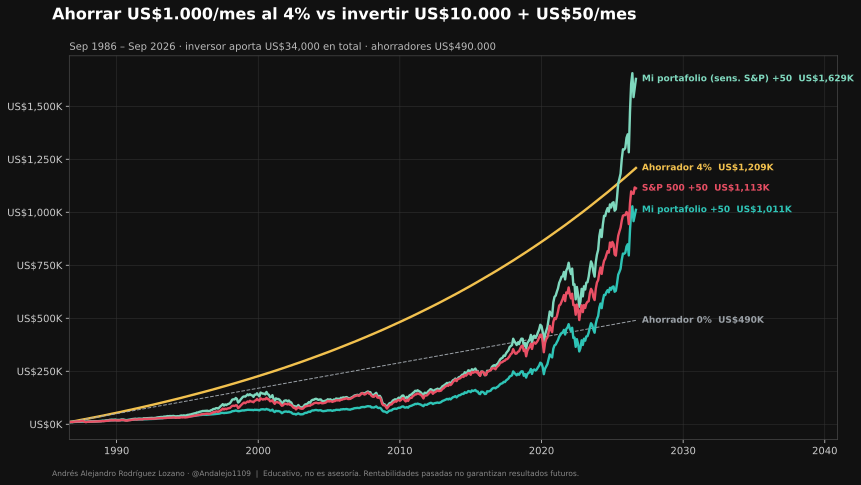

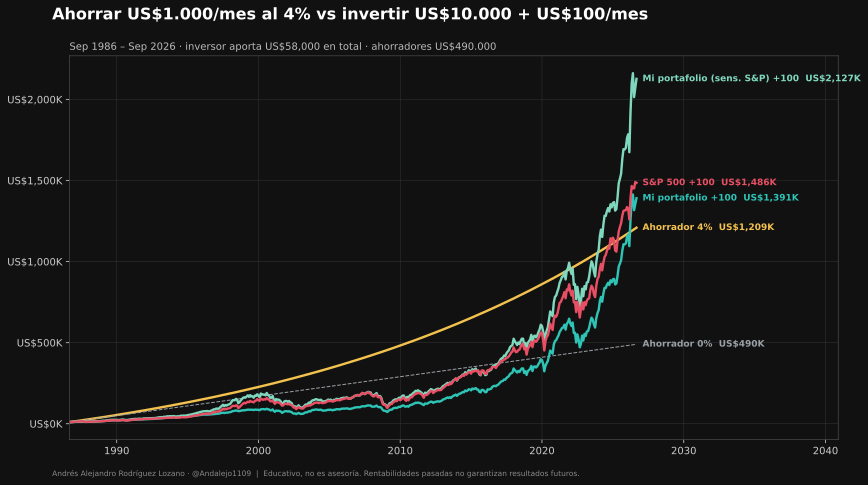

Listo


In [11]:
def carrera(d, ap, n, ax):
    x = d.index[:n+1].to_timestamp()
    cols = dict(zip(d.columns, ['#f2c14e','#9aa0a6','#2ec4b6','#7fd8be','#e94f64']))
    for col,cc in cols.items():
        y = d[col].iloc[:n+1]
        ax.plot(x, y, color=cc, lw=1 if '0%' in col else 2.4, ls='--' if '0%' in col else '-')
        ax.annotate(f'{col}  US${y.iloc[-1]/1e3:,.0f}K', (x[-1], y.iloc[-1]), xytext=(6,0), textcoords='offset points', color=cc, fontsize=9, va='center', weight='bold')
    ax.set_facecolor('#111'); ax.tick_params(colors='#ccc'); ax.grid(color='#333', lw=.5)
    for sp_ in ax.spines.values(): sp_.set_color('#444')
    ax.yaxis.set_major_formatter(lambda v,_: f'US${v/1e3:,.0f}K')
    ax.set_xlim(d.index[0].to_timestamp(), d.index[-1].to_timestamp()+pd.Timedelta(days=5200))
    return cols
TIT = 'Ahorrar US$1.000/mes al 4% vs invertir US$10.000 + US${}/mes'
for ap, d in esc.items():
    fig, ax = plt.subplots(figsize=(12,6.75), facecolor='#111'); cols = carrera(d, ap, 480, ax)
    fig.suptitle(TIT.format(ap), color='w', fontsize=16, weight='bold', x=.06, ha='left')
    ax.set_title(f'Sep 1986 – Sep 2026 · inversor aporta US${CAPITAL+480*ap:,} en total · ahorradores US$490.000', color='#bbb', fontsize=10, loc='left')
    fig.text(.06,.015, FIRMA, color='#888', fontsize=7.5); fig.subplots_adjust(left=.08, right=.97, bottom=.09)
    fig.savefig(f'../figures40/carrera_40anios_aporte{ap}.png', dpi=160, facecolor='#111'); plt.show()
    plt.ioff()
    fig, ax = plt.subplots(figsize=(10,5.6), facecolor='#111'); fig.text(.01,.01, FIRMA, color='#888', fontsize=6)
    def frame(n, d=d, ap=ap):
        ax.clear(); carrera(d, ap, n, ax); ax.set_ylim(0, d.iloc[:n+1].max().max()*1.1)
        ax.set_title(TIT.format(ap)+f' — {d.index[n].strftime("%b %Y")}', color='w', fontsize=11, loc='left')
    FuncAnimation(fig, frame, frames=pasos).save(f'../figures40/carrera_40anios_aporte{ap}.gif', writer=PillowWriter(fps=15), dpi=80)
    plt.close(fig)
    fin = d.iloc[-1].sort_values(ascending=False)
    fig = plt.figure(figsize=(8,8), facecolor='#111')
    fig.text(.5,.9,'40 años después',color='w',fontsize=30,weight='bold',ha='center')
    fig.text(.5,.85,f'Inversor: US$10.000 + US${ap}/mes · sep 1986 – sep 2026',color='#bbb',fontsize=12,ha='center')
    for i,(c,v) in enumerate(fin.items()):
        y=.72-i*.12; fig.text(.08,y,f'{i+1}. {c}',color=cols[c],fontsize=15,weight='bold'); fig.text(.92,y,f'US$ {v:,.0f}',color='w',fontsize=15,ha='right')
    fig.text(.5,.08,f'Aportado: inversores US${CAPITAL+480*ap:,} · ahorradores US$490.000.\nPortafolio: SPYG 30,5% · SMH 21,8% · BRK.B 20,4% · IEMG 20,2% · VTI 7,2%. Meses previos al\nlanzamiento de cada ETF rellenados con su promedio (sin caídas); sens.: S&P 500 real.',color='#999',fontsize=8.5,ha='center')
    fig.text(.5,.02,'Andrés Alejandro Rodríguez Lozano · @Andalejo1109 · Educativo, no es asesoría',color='#888',fontsize=8,ha='center')
    fig.savefig(f'../figures40/ranking_40anios_aporte{ap}.png', dpi=150, facecolor='#111'); plt.close(fig); plt.ion()
print('Listo')

## Conclusiones
- Con un **4% anual garantizado**, el ahorrador (US$1,21M) supera a los tres inversores de un solo pago al cabo de 40 años: aporta US$490.000 frente a US$10.000, y el 4% compuesto sobre aportes constantes pesa mucho. En este ejercicio **ningún inversor cruza al ahorrador del 4%**.
- Contra el ahorrador **al 0%** (el del video) la historia cambia: el S&P 500 y mi portafolio lo terminan superando, pero solo en la recta final.
- **S&P 500 con dividendos reinvertidos:** US$740.695 (el video muestra ~US$621K; solo con precio daría ~US$331K, así que el video probablemente usa una serie intermedia o distintas fechas).
- El valor de mi portafolio depende muchísimo del **relleno** antes de 2000‑2012: US$632K con el promedio de cada ETF vs US$1,13M usando el S&P real. Esto enseña que un backtest largo con activos jóvenes es frágil.
- Con aportes pequeños (+US$50 o +US$100/mes) el inversor mejora mucho su resultado aportando una fracción de lo que aporta el ahorrador; ver el Paso 8 para el aporte de equilibrio que iguala al ahorrador del 4%.
- Mensaje para la clase: no es "ahorrar **o** invertir"; lo poderoso es **invertir el capital inicial y también los aportes mensuales**.

### Ejercicios
1. Cambia la tasa del ahorrador a 6% y encuentra el nuevo cruce.
2. ¿Qué pasa si el ahorrador invierte sus US$1.000 mensuales en el S&P 500?
3. Cambia el rebalanceo a trimestral o elimínalo.

*Andrés Alejandro Rodríguez Lozano · @Andalejo1109 — Contenido educativo, no es asesoría de inversión.*